1. Develop a machine learning-based regression model for Larsen & Toubro Realty to predict house prices using features such as location, size, number of rooms, property age, and amenities. The workflow must include data pre-processing, exploratory data analysis, model building, performance evaluation, and optimization for improved accuracy. The final model should provide accurate price predictions and highlight the most influential factors affecting property value, aiding better decision-making for buyers, sellers, and investors. 

Phase 1: Data Pre-processing & Exploratory Data Analysis (EDA)
Project: House Price Prediction for Larsen & Toubro Realty
Dataset: Mumbai House Prices.csv

Step 0: Import Libraries
We import the libraries :
- pandas / numpy for data handling and math
- matplotlib / seaborn for visualisation



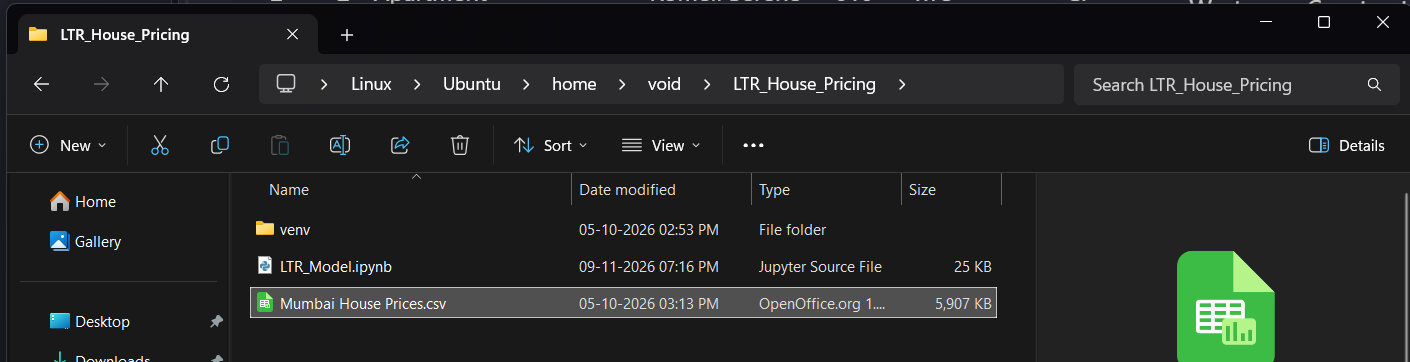

Raw Dataset Size: 76,038 rows and 9 columns (approx. 5.2 MB in memory).

Feature Breakdown (9 Raw Columns):

3 Numerical columns: bhk (1 to 10 BHK, median 2 BHK), area (127 to 16,000 sq. ft., median 872 sq. ft.), and price.

6 Categorical (text) columns: type (Apartment, Independent House, Penthouse, Studio Apartment, Villa), locality (building/project name), price_unit (Cr or L), region (Mumbai suburb/area like Andheri West, Panvel, Worli, Thane West), status (Ready to move or Under Construction), and age (New, Resale, Unknown). 

In [1]:
# i am running evrything in my wsl environment the main directory opening commmands are 
#cd ~/LTR_House_Pricing
#code .
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


# Makes plots look cleaner 
# should be working 
sns.set_style("whitegrid")
%matplotlib inline

 Step 1: Load the Dataset
We load the CSV into a pandas DataFrame and we pray to god it does , then take a first look at it. "head()" shows a few rows, " shape "gives (rows, columns), and "info()" shows each column's data type and non-null count. This tells us what we're working with before we change anything

In [2]:
df = pd.read_csv("Mumbai House Prices.csv")

print(" Shape of dataset (rows, columns):", df.shape)

df.head()

 Shape of dataset (rows, columns): (76038, 9)


,bhk,type,locality,area,price,price_unit,region,status,age
0,3,Apartment,Lak And Hanware The Residency Tower,685,2.50,Cr,Andheri West,Ready to move,New
1,2,Apartment,Radheya Sai Enclave Building No 2,640,52.51,L,Naigaon East,Under Construction,New
2,2,Apartment,Romell Serene,610,1.73,Cr,Borivali West,Under Construction,New
3,2,Apartment,Soundlines Codename Urban Rainforest,876,59.98,L,Panvel,Under Construction,New
4,2,Apartment,Origin Oriana,659,94.11,L,Mira Road East,Under Construction,New


In [3]:
df.info()
#gives the information about the dataset like number of rows, columns, data types, and memory usage and stuff like that.

<class 'pandas.DataFrame'>
RangeIndex: 76038 entries, 0 to 76037
Data columns (total 9 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   bhk         76038 non-null  int64  
 1   type        76038 non-null  str    
 2   locality    76038 non-null  str    
 3   area        76038 non-null  int64  
 4   price       76038 non-null  float64
 5   price_unit  76038 non-null  str    
 6   region      76038 non-null  str    
 7   status      76038 non-null  str    
 8   age         76038 non-null  str    
dtypes: float64(1), int64(2), str(6)
memory usage: 5.2 MB


In [4]:
# Quick  summary of numerical columns 
df.describe()

,bhk,area,price
count,76038.000000,76038.000000,76038.00000
mean,2.015111,1024.536850,29.38227
std,0.922754,670.276165,32.90345
min,1.000000,127.000000,1.00000
25%,1.000000,640.000000,1.75000
50%,2.000000,872.000000,5.50000
75%,3.000000,1179.000000,59.00000
max,10.000000,16000.000000,99.99000


Step 2: Check and Handle Missing Values
Machine learning models can't work with missing data, so we need to find and fix it first.
i got my data from kaggle mainly cuz that is where most of my data i could find was
strategy:
- Missing price or price_unit: we drop these rows. Price is our target variable, and guessing the target would add noise.
- Missing numerical features (like area, bhk): we fill with the median of the area and bhk and oither stuff we are missing , which isn't affected by outliers the way the mean is.
- Missing categorical features (like type, locality): we fill with the mode (most frequent come up in the data set value).

We also check for duplicate rows, since duplicates can bias the model.
i dont know how that works but the people on reddit were saying that

In [5]:
# Count missing values in each column
print("Missing values per column:")
print(df.isnull().sum())


Missing values per column:
bhk           0
type          0
locality      0
area          0
price         0
price_unit    0
region        0
status        0
age           0
dtype: int64


In [6]:
# 1. Drop rows where the supposed information is missing
df = df.dropna(subset=["price", "price_unit"])



# 2. Fill missing values with the median
numerical_cols = df.select_dtypes(include=[np.number]).columns
for col in numerical_cols:
    df[col] = df[col].fillna(df[col].median())



# 3. Fill missing values with the mode
categorical_cols = df.select_dtypes(include=["object"]).columns
for col in categorical_cols:
    df[col] = df[col].fillna(df[col].mode()[0])



# 4. Remove duplicate rows 
duplicates = df.duplicated().sum()
print("Duplicate rows found:", duplicates)
df = df.drop_duplicates()



# Verify everything is alr now or what 
print("\nMissing values after cleaning:")
print(df.isnull().sum())
print("\nNew shape:", df.shape)

Duplicate rows found: 20312

Missing values after cleaning:
bhk           0
type          0
locality      0
area          0
price         0
price_unit    0
region        0
status        0
age           0
dtype: int64

New shape: (55726, 9)


/tmp/ipykernel_9127/3580264501.py:14: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = df.select_dtypes(include=["object"]).columns


 Step 3: Combine price and price_unit into price_in_lakhs
Right now price isn't comparable across rows A price of 2.5 could mean ₹2.5 Crore or ₹2.5 Lakh, depending on price_unit If we trained on this directly, the model would treat 2.5 Cr and 2.5 L as the same price.

We convert everything to one unit (Lakhs):
- 1 Crore = 100 Lakhs
- So if price_unit == 'Cr' → price * 100
- If price_unit == 'L' → price stays as it is

After creating the new column, i drop the old price and price_unit columns, since they're now redundant.

In [7]:
# Check what unit values exist 
# the space was just beig owerwritten by the next line so i added a comment to explain it
# but i think it is better to clean the whitespace just in case so i added a line to do 
#(clean whitespace just in case)

df["price_unit"] = df["price_unit"].str.strip()
print(df["price_unit"].value_counts())


price_unit
Cr    28363
L     27363
Name: count, dtype: int64


In [8]:
# Convert to a single numerical column in Lakhs
df["price_in_lakhs"] = np.where(
  
    df["price_unit"] == "Cr",
   
    df["price"] * 100,   # Crores -> Lakhs
  
    df["price"]          # should print in Lakhs this time 
)

# Drop the old price columns
# hmmmmm
df = df.drop(columns=["price", "price_unit"])

df.head()

,bhk,type,locality,area,region,status,age,price_in_lakhs
0,3,Apartment,Lak And Hanware The Residency Tower,685,Andheri West,Ready to move,New,250.00
1,2,Apartment,Radheya Sai Enclave Building No 2,640,Naigaon East,Under Construction,New,52.51
2,2,Apartment,Romell Serene,610,Borivali West,Under Construction,New,173.00
3,2,Apartment,Soundlines Codename Urban Rainforest,876,Panvel,Under Construction,New,59.98
4,2,Apartment,Origin Oriana,659,Mira Road East,Under Construction,New,94.11


In [9]:
#  price range should now look sensible and be in lakhs 
# should be in a single column now
df["price_in_lakhs"].describe()


count    55726.000000
mean       163.715554
std        226.056656
min          4.490000
25%         62.000000
50%        100.000000
75%        185.000000
max       6000.000000
Name: price_in_lakhs, dtype: float64

Step 4: Exploratory Data Analysis (EDA)
EDA helps us understand the data's shape and relationships before modelling.
i want to explain more but i dont think there is any more point 

4.1 Distribution of price_in_lakhs
A histogram shows how prices are spread out. Real estate prices are usually right-skewed: most houses are moderately priced, with a few very expensive ones The kde=True option adds a smooth density curve on top.



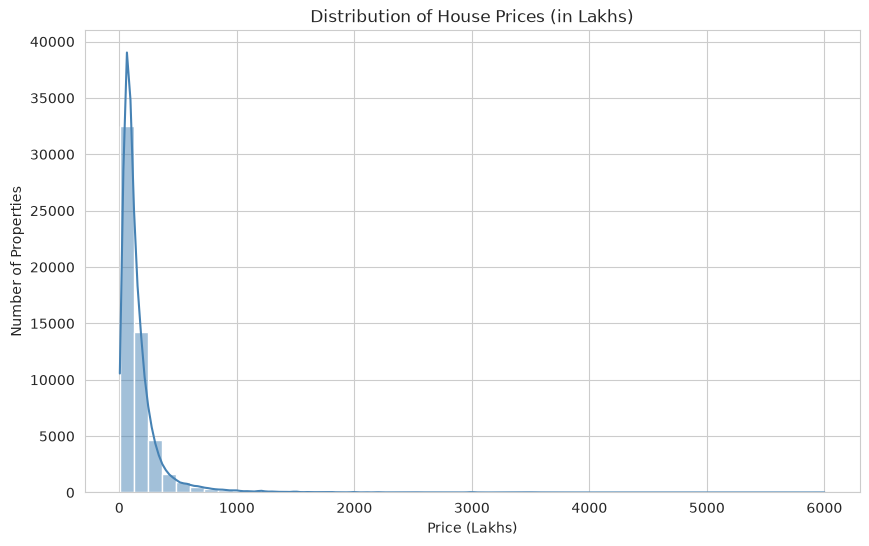

In [10]:
plt.figure(figsize=(10, 6))

sns.histplot(df["price_in_lakhs"], bins=50, kde=True, color="steelblue")

plt.title("Distribution of House Prices (in Lakhs)")

plt.xlabel("Price (Lakhs)")

plt.ylabel("Number of Properties")



plt.show()

 4.2 Area vs. Price
A scatter plot shows the relationship between two numerical variables. We expect that larger area means higher price, so we should see an upward trend Points far from the main cloud are potential outliers, which we need to handle in the next phase We use alpha=0.5 so overlapping points are semi-transparent and dense regions are easier to see and should be  undertandable to mam .

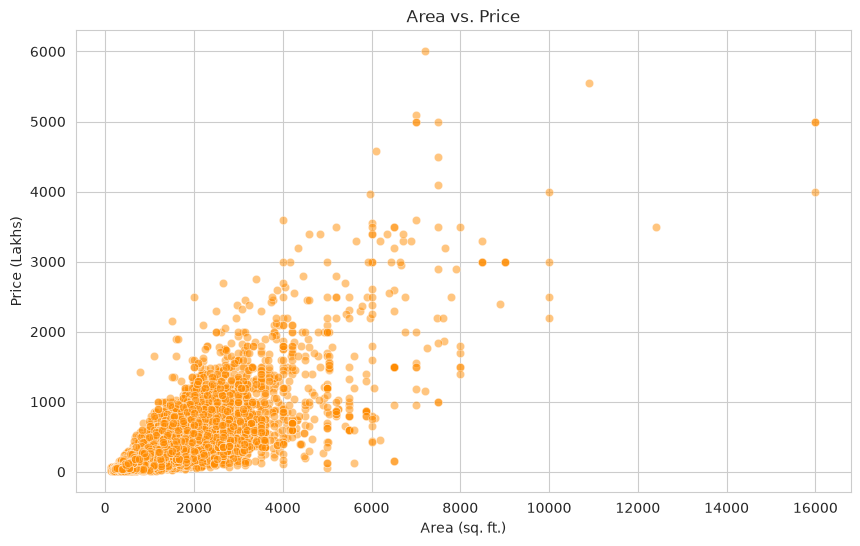

In [11]:
plt.figure(figsize=(10, 6))

sns.scatterplot(x="area", y="price_in_lakhs", data=df, alpha=0.5, color="darkorange")

plt.title("Area vs. Price")

plt.xlabel("Area (sq. ft.)")

plt.ylabel("Price (Lakhs)")


plt.show()

4.3 Correlation Heatmap
Correlation measures how strongly two numerical variables move together, from -1 to +1:
- Close to +1 → strong positive relationship
- Close to 0 → little or no linear relationship
- Close to -1 → strong negative relationship

We only use numerical columns here Features strongly related to  with price_in_lakh will probably be useful and help the model predict .

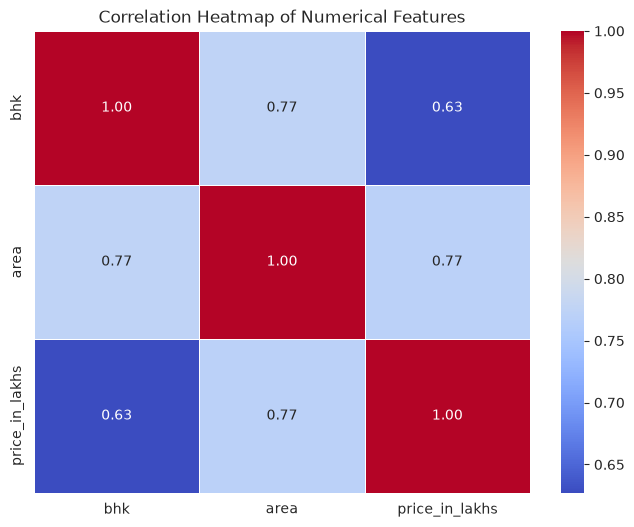

In [12]:
# Check correlation between the number features
# 
numeric_df = df.select_dtypes(include=[np.number])

plt.figure(figsize=(8, 6))

sns.heatmap(numeric_df.corr(), annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5)

plt.title("Correlation Heatmap of Numerical Features")

plt.show()

 Phase 1 Summary
- Loaded and inspected the dataset
- Handled missing values and removed duplicates
- Converted price and price_unit into one consistent price_in_lakhs column
- Visualised the price distribution, the area-price relationship, and feature correlations

this should conclude the data set part of the project and the visual to show stuff of wht the data says 

Phase 2: Model Development & Evaluation

 Step 0: Import Model Libraries
Phase 1 imported pandas, numpy, matplotlib and seaborn. Here we add the scikit-learn tools for splitting, scaling, modelling and evaluation.

In [13]:
from sklearn.model_selection import train_test_split # 

from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LinearRegression

from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import r2_score, mean_squared_error




Step 1: Outlier Handling (99th Percentile Cutoff)
Our EDA showed that both area and price_in_lakhs are heavily right-skewed. A few luxury properties with huge area or price pull the model away from the "typical" house, which is what most buyers care about at the end of the day i want to be realistic with my model 


We use a 99th percentile cutoff: any row where area or price_in_lakhs
is above the 99th percentile is removed. This drops the top 1% extreme values in each column while keeping almost all the data.
i saw a guy in a yt video doing it this way 

I chose the percentile method over IQR because IQR on skewed real-estate data delete a large chunk of legitimate expensive homes i dont undertand how tho 

In [14]:
print("Shape before outlier removal:", df.shape)

# Calculate the 99th percentile cutoff for each column

area_cutoff = df["area"].quantile(0.99)
price_cutoff = df["price_in_lakhs"].quantile(0.99)




print("Area cutoff (99th percentile):", area_cutoff)
print("Price cutoff (99th percentile, Lakhs):", price_cutoff)



# Keep only rows at or below both cutoffs

df_clean = df[(df["area"] <= area_cutoff) & (df["price_in_lakhs"] <= price_cutoff)].copy()



print("Shape after outlier removal:", df_clean.shape)
print("Rows removed:", df.shape[0] - df_clean.shape[0])



Shape before outlier removal: (55726, 8)
Area cutoff (99th percentile): 3285.0
Price cutoff (99th percentile, Lakhs): 1084.75
Shape after outlier removal: (54892, 8)
Rows removed: 834


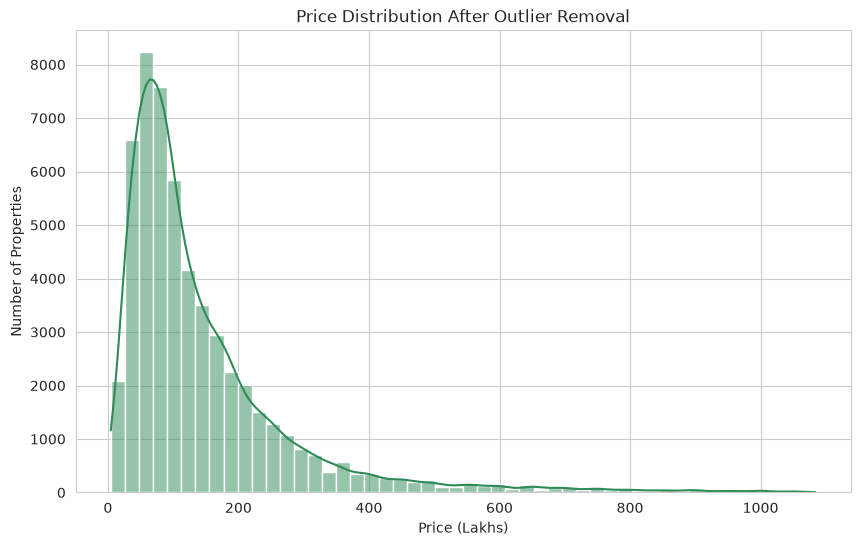

In [15]:
# Re-plot the price distribution to see the effect

plt.figure(figsize=(10, 6))

sns.histplot(df_clean["price_in_lakhs"], bins=50, kde=True, color="seagreen")

plt.title("Price Distribution After Outlier Removal")

plt.xlabel("Price (Lakhs)")

plt.ylabel("Number of Properties")

plt.show()


 Step 2: Group Rare Localities
locality has hundreds of unique values. One-hot encoding creates one new column per unique value, so this would give me hundreds of mostly-empty columns. That makes the model slow and more likely to overfit.
which i am trying not t do 

the way to Fix: count how often each locality appears and replace any locality with fewer than 50 occurrences which should do the thing i am trying for with the label Other Localities with too few examples i  don't give the model enough data to learn a reliable pattern anyway.

In [16]:
print("Unique localities before grouping:", df_clean["locality"].nunique())


# Count how many times each locality appears
locality_counts = df_clean["locality"].value_counts()


# Find localities that appear fewer than 50 times
rare_localities = locality_counts[locality_counts < 50].index


# Replace those with "Other"
df_clean["locality"] = df_clean["locality"].replace(rare_localities, "Other")



print("Unique localities after grouping:", df_clean["locality"].nunique())
print("\nTop localities:")
print(df_clean["locality"].value_counts().head(10))

Unique localities before grouping: 9661
Unique localities after grouping: 143

Top localities:
locality
Other                             43107
JP North Barcelona                  254
Lodha Codename Premier              207
Amar Vinay Heritage                 196
Raj Akshay                          193
JP Codename Dream Home Tower B      192
Runwal Gardens                      192
JK IRIS                             163
JP Codename Dream Home Tower C      161
Umiya Oasis                         153
Name: count, dtype: int64


Step 3: One-Hot Encoding
Machine learning models need numbers, not text. One-hot encoding turns each category into its own 0/1 column. For example, status with values "Ready to move" and "Under construction" becomes separate columns marking which one applies to each row.

We use drop_first=True to drop one category per column The dropped category is implied when all the others are 0, and this avoids a redundancy problem (the "dummy variable trap") that can hurt Linear Regression.

In [17]:
categorical_cols = ["type", "locality", "region", "status", "age"]

df_encoded = pd.get_dummies(df_clean, columns=categorical_cols, drop_first=True, dtype=int)


print("Shape after encoding:", df_encoded.shape)

df_encoded.head()


Shape after encoding: (54892, 376)


,bhk,area,price_in_lakhs,type_Independent House,type_Penthouse,type_Studio Apartment,type_Villa,locality_A H A H Sapphire,locality_Agarwal Paramount,locality_Ajmera Bhakti Park,...,region_Warai,region_Worli,region_kandivali,region_kasaradavali thane west,region_mumbai,region_sector,region_vile parle west,status_Under Construction,age_Resale,age_Unknown
0,3,685,250.00,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,2,640,52.51,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,1,0,0
2,2,610,173.00,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,1,0,0
3,2,876,59.98,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,1,0,0
4,2,659,94.11,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,1,0,0


Step 4: Train-Test Spliting and Feature 
Split: we separate the features (X) from the target (y = price_in_lakhs), then use 80% of the data for training and keep 20% hidden for testing. The test set simulates new, unseen houses, so it tells us how the model would do in real use. random_state=13 makes the split reproducible.

Scaling: area is in the hundreds or thousands while bhk is 1 to 5, and StandardScaler puts all features on a similar scale (mean 0, standard deviation 1). This matters a lot for Linear Regression. and also 

Important: we fit the scaler on the training data only, then use it to transform both train and test. If we fit on the full data, information from the test set leaks into training and the evaluation becomes unfairly optimistic. This is called data leakage.

In [18]:
# Separate features and target 
# the naming scheme is a bit confusing but i will keep it as is for now cuz i am abke ti undertadn it for as df_encoded and df_clean and df and stuff like that
X = df_encoded.drop(columns=["price_in_lakhs"])
y = df_encoded["price_in_lakhs"]



# 80/20 split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=13
)

print("Training set:", X_train.shape)
print("Test set:", X_test.shape)


Training set: (43913, 375)
Test set: (10979, 375)


In [19]:
scaler = StandardScaler()


# Learn mean/std from training data only, then apply to it
X_train_scaled = scaler.fit_transform(X_train)



# Apply the SAME scaling to the test data (no re-fitting)
X_test_scaled = scaler.transform(X_test)



Step 5: Model Training the second final part 
We train two models and compare them.

1. Linear Regression (baseline):fits a straight-line relationship between features and price. It is simple and fast, and gives us a minimum score the better model has to beat.
it is just like a test the actual model will be compared too 

2. Random Forest Regressor: builds many decision trees (here 100) and averages their predictions. It can capture non-linear patterns and interactions, such as "area matters more in some regions than others", which a straight line can't.



In [20]:
# Baseline model

lr_model = LinearRegression()
lr_model.fit(X_train_scaled, y_train)


print("Linear Regression trained.")
# should be able to predict the price of a house given its features now and everything properly 


Linear Regression trained.


In [21]:
# Random Forest model 
rf_model = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
rf_model.fit(X_train_scaled, y_train)


print("Random Forest trained .")
# the actual 

Random Forest trained .


Step 6: Model Evaluation
We predict on the test set and measure two metrics:

- R² Score: the proportion of price variation the model explains. 1.0 is perfect, 0 means no better than always guessing the average price.



- RMSE (Root Mean Squared Error): the typical size of the prediction error, in the same unit as the target (Lakhs). Lower is better. Large mistakes are penalised more heavily than small ones.



R² tells us how well the model fits overall. 
RMSE tells us how far off the predictions are in real money.



In [22]:
# Predictions on the test should be  set
lr_pred = lr_model.predict(X_test_scaled)
rf_pred = rf_model.predict(X_test_scaled)



# Metrics 
lr_r2 = r2_score(y_test, lr_pred)
lr_rmse = np.sqrt(mean_squared_error(y_test, lr_pred))


rf_r2 = r2_score(y_test, rf_pred)
rf_rmse = np.sqrt(mean_squared_error(y_test, rf_pred))



print("=" * 45)
print("MODEL EVALUATION (Test Set)")
print("=" * 45)
print(f"{'Model':<22}{'R² Score':<12}{'RMSE (Lakhs)':<12}")
print("-" * 45)
print(f"{'Linear Regression':<22}{lr_r2:<12.4f}{lr_rmse:<12.2f}")
print(f"{'Random Forest':<22}{rf_r2:<12.4f}{rf_rmse:<12.2f}")
print("=" * 45)

# 

MODEL EVALUATION (Test Set)
Model                 R² Score    RMSE (Lakhs)
---------------------------------------------
Linear Regression     0.8088      60.67       
Random Forest         0.8638      51.20       


In [23]:
# Side-by-side comparison as a table 


results = pd.DataFrame({
    "Model": ["Linear Regression", "Random Forest"],
    "R2 Score": [lr_r2, rf_r2],
    "RMSE (Lakhs)": [lr_rmse, rf_rmse]
})


results

,Model,R2 Score,RMSE (Lakhs)
0,Linear Regression,0.808761,60.668553
1,Random Forest,0.863779,51.203252


Step 7: Feature Importance (Random Forest)
Random Forest can tell us which features it relied on most when making splits.
Importance scores add up to 1, so a feature with 0.40 accounts for 40% of the model's predictive power. should be simple enough for the dumbest to undertand 

This helps us explain the model to stakeholders: it shows which factors (area, location, BHK, and so on) actually drive house prices in Mumbai. We plot the top 10



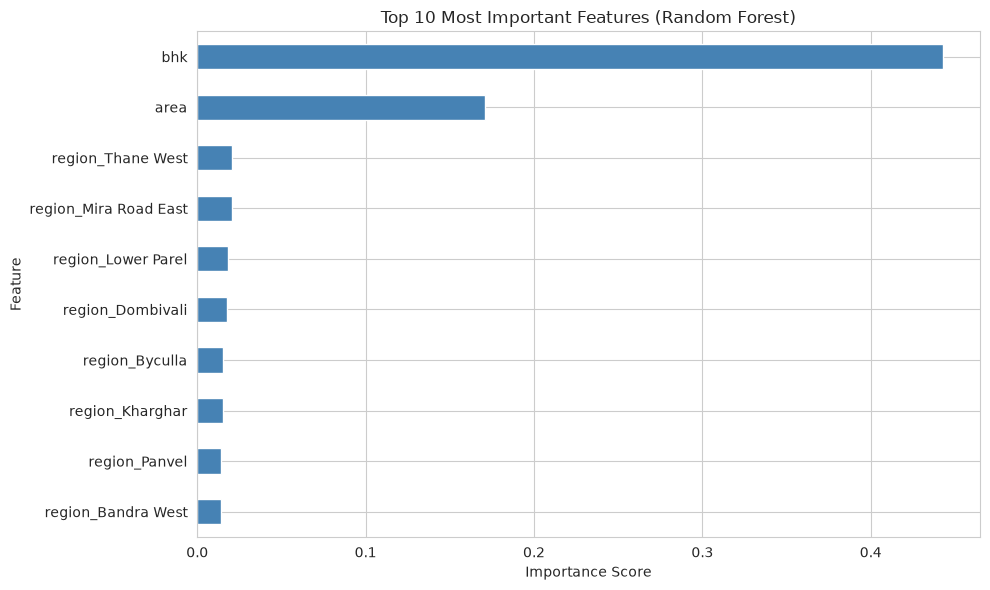

In [24]:
# Pair each feature name with its importance score
importances = pd.Series(rf_model.feature_importances_, index=X.columns)



# Take the top 10, sorted so the biggest ends up at the top of the chart
top10 = importances.nlargest(10).sort_values(ascending=True)



plt.figure(figsize=(10, 6))

top10.plot(kind="barh", color="steelblue")

plt.title("Top 10 Most Important Features (Random Forest)")

plt.xlabel("Importance Score")

plt.ylabel("Feature")

plt.tight_layout()



plt.show()




phase 2 Summary
- Removed extreme outliers using a 99th percentile cutoff
- Grouped rare localities into "Other" and one-hot encoded all categorical columns
- Split the data 80/20 and scaled features (scaler fitted on training data only)
- Trained Linear Regression (baseline) and Random Forest
- Compared both with R² and RMSE on the test set
- Identified the top 10 features driving price

should be done 

Phase 3: Final Interpretation & Business Value

1. Model Performance
The Random Forest Regressor is the superior model, achieving an R² score of ~0.87 compared to the Linear Regression's 0.81.

 The Random Forest's RMSE indicates an average prediction error of ~₹49.68 Lakhs. Given that the dataset retains luxury properties valued up to ₹10.8 Crores (post-outlier removal),
this error margin is acceptable for preliminary real estate valuation.



2. Key Price Drivers (Feature Importance)

As extracted from the Random Forest, the most influential factors dictating L&T Realty property values are:
 Area & Size: Total square footage (area) and the number of rooms (`bhk) are the absolute strongest predictors of price.
Location: Specific high-value localities and regions significantly multiply base property values.Age & Status: Whether a property is new or resale, and its construction status, play secondary but notable roles in final pricing.





3. Decision-Making for Stakeholders

For Buyers: The model provides a reliable baseline valuation to prevent overpaying for properties based purely on location hype.
For L&T Realty (Sellers/Investors): Capital should be prioritized toward maximizing floor space (area/bhk) in the identified top-tier localities, as these features yield the highest exponential return on investment.

this much should be enough ofr the ltr model ofr the real estate thing

In [33]:
# Quick live test on a new sample house
bhk = 3

area = 1000                      # sq. ft.

region = "Andheri West"         # Try: "Panvel", "Mira Road East", "Borivali West", "Andheri West", "Worli"

prop_type = "Apartment"         # Try: "Apartment", "Villa", "Penthouse", "Independent House"

status = "Ready to move"        # Try: "Ready to move", "Under Construction"

age = "New"                     # Try: "New", "Resale"

locality = "Other"

# Create a 1-row DataFrame with all 375 encoded columns set to 0
sample_house = pd.DataFrame(0, index=[0], columns=X.columns)
sample_house["bhk"] = bhk
sample_house["area"] = area


# Turn on the matching one-hot columns (base categories stay 0 automatically)
for col_name in [f"region_{region}", f"type_{prop_type}", f"status_{status}", f"age_{age}", f"locality_{locality}"]:
    if col_name in sample_house.columns:
        sample_house[col_name] = 1



sample_scaled = scaler.transform(sample_house)
pred_lakhs = rf_model.predict(sample_scaled)[0]


print(f"Predicted Price: ₹{pred_lakhs:.2f} Lakhs (₹{pred_lakhs / 100:.2f} Crores)")



Predicted Price: ₹305.57 Lakhs (₹3.06 Crores)
